In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from alerce.core import Alerce
client = Alerce()

In [2]:
#Another ZTF object to query, not used in this notebook, but can be used to test the code
# object_info = client.query_objects(
#     oid = "ZTF18abkkgap",
#     survey = "ztf",
#     format = "pandas"
# )
# DataFrame = pd.DataFrame(object_info)
# DataFrame.head()
#oid2: ZTF18aasycma


In [14]:
lc = client.query_lightcurve("ZTF18aasycma", format = "pandas", survey="ztf")
lc_detections = lc["detections"]
detections_list = lc_detections.iloc[0]
df = pd.DataFrame(detections_list)
df.head()
df["dubious"].value_counts()
clean_df = df[(~df["dubious"]) & (df["corrected"])]
clean_df["magpsf_corr"].isna().sum()

np.int64(0)

In [4]:
len(clean_df)

1332

In [ ]:
print(clean_df.columns)

Index(['tid', 'mjd', 'candid', 'fid', 'pid', 'diffmaglim', 'isdiffpos', 'nid',
       'distnr', 'magpsf', 'magpsf_corr', 'magpsf_corr_ext', 'magap',
       'magap_corr', 'sigmapsf', 'sigmapsf_corr', 'sigmapsf_corr_ext',
       'sigmagap', 'sigmagap_corr', 'ra', 'dec', 'rb', 'rbversion', 'drb',
       'magapbig', 'sigmagapbig', 'rfid', 'has_stamp', 'corrected', 'dubious',
       'candid_alert', 'step_id_corr', 'phase', 'parent_candid'],
      dtype='str')


In [15]:
clean_df["fid"].unique()
#fid: 1 = g 2 = r 3 = i
g_df = clean_df[clean_df["fid"] == 1]
r_df = clean_df[clean_df["fid"] == 2]
i_df = clean_df[clean_df["fid"] == 3]

print(len(g_df), len(r_df), len(i_df))


705 625 2


In [ ]:
clean_df["sigmapsf_corr"].describe() 
#The sigmapsf_corr column contained many placeholder values (default 100) which threw off the error bar. 
# Need to use sigmapsf_corr_ext

count    1332.000000
mean       41.077474
std        49.204326
min         0.000370
25%         0.015004
50%         0.029177
75%       100.000000
max       100.000000
Name: sigmapsf_corr, dtype: float64

In [19]:
clean_df["sigmapsf_corr_ext"].describe()

count    1332.000000
mean        0.027445
std         0.012708
min         0.005252
25%         0.019752
50%         0.025611
75%         0.032849
max         0.256209
Name: sigmapsf_corr_ext, dtype: float64

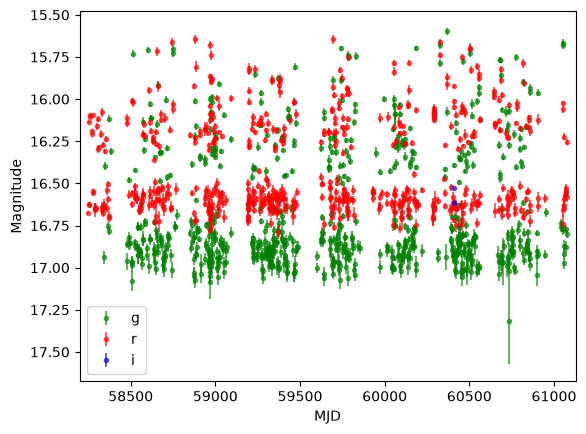

In [20]:
mjdstarthist = clean_df["mjd"].min() - 50
mjdendhist = clean_df["mjd"].max() + 50

fig, axs = plt.subplots()
axs.set_xlabel("MJD")
axs.set_ylabel("Magnitude")
axs.set_xlim(mjdstarthist, mjdendhist)
axs.errorbar(g_df["mjd"], g_df["magpsf_corr"], yerr=g_df["sigmapsf_corr_ext"], fmt="o", label="g", color="green", ms = 3, alpha = 0.6)
axs.errorbar(r_df["mjd"], r_df["magpsf_corr"], yerr=r_df["sigmapsf_corr_ext"], fmt="o", label="r", color="red",  ms = 3, alpha = 0.6)
if len(i_df) > 0:
    axs.errorbar(i_df["mjd"], i_df["magpsf_corr"], yerr=i_df["sigmapsf_corr_ext"], fmt="o", label="i", color="blue", ms = 3, alpha = 0.6)
axs.legend()
axs.invert_yaxis()